# DS201 - Lab 1: Mạng neural cơ bản (MLP) trên MNIST
## Bản thực hành tại lớp

Vừa nghe giảng vừa điền vào các chỗ `______`. Thứ tự các mục khớp với file đề `Lab 1.pdf`.

| Ký hiệu | Nghĩa |
|---|---|
| `______` kèm `# TODO n:` | Phần bạn tự viết. Chạy ô khi chưa điền sẽ báo `NameError: name '______' is not defined` |
| `assert ...` | Dòng tự kiểm tra. Không báo gì là đúng, báo `AssertionError` là còn sai |



## A.1. Kiểm tra môi trường

In [1]:
import torch, torchvision, sklearn, matplotlib

print("torch       :", torch.__version__)
print("torchvision :", torchvision.__version__)
print("scikit-learn:", sklearn.__version__)
print("GPU         :", torch.cuda.is_available())

torch       : 2.14.1
torchvision : 0.29.1
scikit-learn: 1.9.1
GPU         : False


## A.2. Làm quen với tensor và nạp MNIST

In [2]:
x = torch.tensor([[1., 2., 3.],
                  [4., 5., 6.]])
print(x.shape, x.dtype)
print(x.view(3, 2))      # đổi shape
print(x @ x.T)           # [2,3] @ [3,2] -> [2,2]

torch.Size([2, 3]) torch.float32
tensor([[1., 2.],
        [3., 4.],
        [5., 6.]])
tensor([[14., 32.],
        [32., 77.]])


In [3]:
from torchvision import datasets, transforms

train_full = datasets.MNIST(root="data", train=True,  download=True,
                            transform=transforms.ToTensor())
test_ds    = datasets.MNIST(root="data", train=False, download=True,
                            transform=transforms.ToTensor())

print("Train:", train_full.data.shape, "| Test:", test_ds.data.shape)
print("Kiểu gốc:", train_full.data.dtype,
      "| pixel gốc:", train_full.data.min().item(),
      "->", train_full.data.max().item())

Train: torch.Size([60000, 28, 28]) | Test: torch.Size([10000, 28, 28])
Kiểu gốc: torch.uint8 | pixel gốc: 0 -> 255


In [4]:
img, label = train_full[0]
print("shape:", img.shape, "| min/max:", img.min().item(), img.max().item(),
      "| nhãn:", label)

shape: torch.Size([1, 28, 28]) | min/max: 0.0 1.0 | nhãn: 5


**CỐ Ý GÂY LỖI:** vẽ thẳng tensor `[1, 28, 28]`.

TypeError: Invalid shape (1, 28, 28) for image data

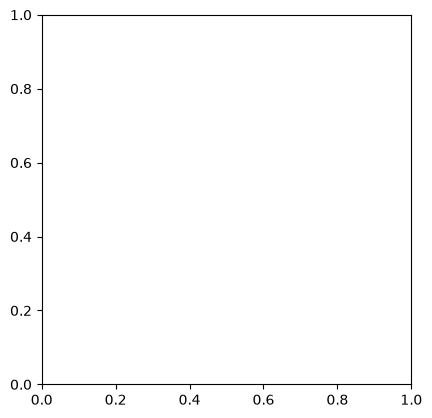

In [5]:
import matplotlib.pyplot as plt

plt.imshow(img, cmap="gray")

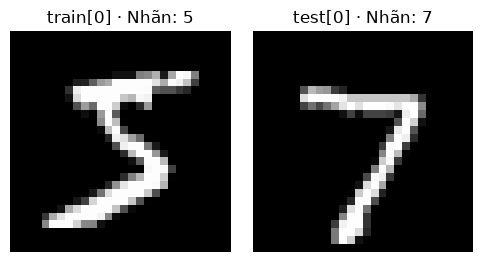

In [6]:
pairs = [(train_full, "train[0]"), (test_ds, "test[0]")]
fig, axes = plt.subplots(1, 2, figsize=(5, 2.6))
for ax, (ds, name) in zip(axes, pairs):
    img, label = ds[0]
    ax.imshow(img.squeeze(0), cmap="gray")   # [1,28,28] -> [28,28]
    ax.set_title(f"{name} - Nhãn: {label}")
    ax.axis("off")
plt.tight_layout(); plt.show()

In [7]:
train_counts = torch.bincount(train_full.targets, minlength=10)
test_counts  = torch.bincount(test_ds.targets,    minlength=10)

print("Chữ số | Train | Test")
for d in range(10):
    tr, te = train_counts[d].item(), test_counts[d].item()
    print(f"{d:>6} | {tr:>5} | {te:>4}")

Chữ số | Train | Test
     0 |  5923 |  980
     1 |  6742 | 1135
     2 |  5958 | 1032
     3 |  6131 | 1010
     4 |  5842 |  982
     5 |  5421 |  892
     6 |  5918 |  958
     7 |  6265 | 1028
     8 |  5851 |  974
     9 |  5949 | 1009


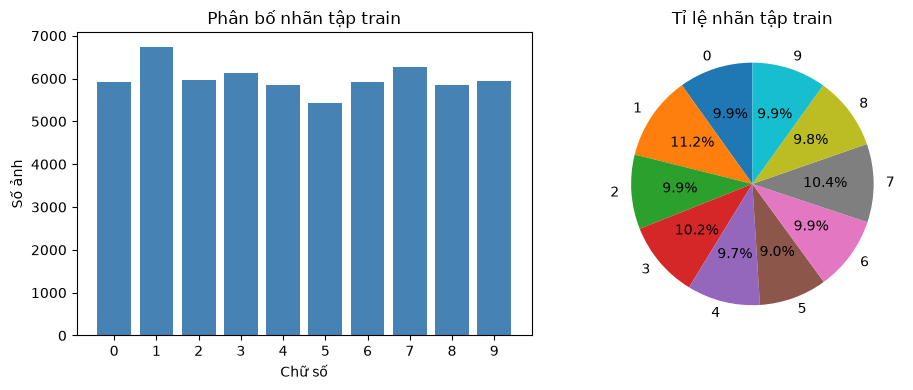

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.bar(range(10), train_counts.numpy(), color="steelblue")
ax1.set_xticks(range(10))
ax1.set_xlabel("Chữ số"); ax1.set_ylabel("Số ảnh")
ax1.set_title("Phân bố nhãn tập train")

ax2.pie(train_counts.numpy(), labels=range(10), autopct="%.1f%%",
        startangle=90)
ax2.set_title("Tỉ lệ nhãn tập train")
plt.tight_layout(); plt.show()

## PHẦN B - Ô dùng chung (chạy trước mọi mục B.x)

Chuẩn hoá theo mean/std của MNIST, tách 54,000 train / 6,000 validation, batch 64, seed 42.

In [9]:
import random, time
import numpy as np
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

set_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"

tf = transforms.Compose([
    transforms.ToTensor(),                        # [0,255] -> [0,1]
    transforms.Normalize((0.1307,), (0.3081,)),   # mean/std của MNIST
])
train_full = datasets.MNIST("data", train=True,  download=True,
                            transform=tf)
test_ds    = datasets.MNIST("data", train=False, download=True,
                            transform=tf)

g = torch.Generator().manual_seed(42)
train_ds, val_ds = random_split(train_full, [54000, 6000], generator=g)

BATCH = 64
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True,
                          generator=torch.Generator().manual_seed(42))
val_loader   = DataLoader(val_ds,  batch_size=256)
test_loader  = DataLoader(test_ds, batch_size=256)

print("device:", device)
print("train / val / test:", len(train_ds), len(val_ds), len(test_ds))

device: cpu
train / val / test: 54000 6000 10000


## B.1. Neuron, lớp và shape

In [10]:
# TODO 1: một neuron 784 -> 1
neuron = nn.Linear(784, 1)
print("weight:", neuron.weight.shape, "| bias:", neuron.bias.shape)
print("Số tham số:", sum(p.numel() for p in neuron.parameters()))

assert sum(p.numel() for p in neuron.parameters()) == 785

weight: torch.Size([1, 784]) | bias: torch.Size([1])
Số tham số: 785


In [11]:
def count_params(model):
    return sum(p.numel() for p in model.parameters())

set_seed(42)
# TODO 2: MLP 784 -> 128 -> 10, lớp cuối trả logits
mlp = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 128),
    nn.ReLU(),
    nn.Linear(128, 10),
)
for name, p in mlp.named_parameters():
    print(f"{name:10s} {str(list(p.shape)):12s} {p.numel():>7,}")
print(f"{'Tổng':23s} {count_params(mlp):>7,}")

assert count_params(mlp) == 101_770, "Mô hình phải có 101,770 tham số"

1.weight   [128, 784]   100,352
1.bias     [128]            128
3.weight   [10, 128]      1,280
3.bias     [10]              10
Tổng                    101,770


In [12]:
x, y = next(iter(train_loader))
print(f"{'input':10s}", list(x.shape))
h = x
for layer in mlp:
    h = layer(h)           # TODO 3: cho h qua layer
    print(f"{layer.__class__.__name__:10s}", list(h.shape))

input      [64, 1, 28, 28]
Flatten    [64, 784]
Linear     [64, 128]
ReLU       [64, 128]
Linear     [64, 10]


**CỐ Ý GÂY LỖI:** quên `nn.Flatten()`.

In [13]:
no_flatten = nn.Sequential(nn.Linear(784, 128), nn.ReLU(),
                           nn.Linear(128, 10))
no_flatten(x)

RuntimeError: mat1 and mat2 shapes cannot be multiplied (1792x28 and 784x128)

## B.2. Vì sao cần hàm phi tuyến

In [14]:
set_seed(0)
deep_linear = nn.Sequential(nn.Linear(4, 16), nn.Linear(16, 16),
                            nn.Linear(16, 2))
x4 = torch.randn(5, 4)

# gộp cả chuỗi thành một phép affine W x + b
L0, L1, L2 = deep_linear
# TODO 4: gộp 3 lớp thành một phép affine W x + b
W = L2.weight @ L1.weight @ L0.weight
b = L2.weight @ (L1.weight @ L0.bias + L1.bias) + L2.bias

print("Số tham số deep_linear:", count_params(deep_linear))
print("Shape W gộp:", list(W.shape),
      "-> tương đương nn.Linear(4, 2), chỉ 10 tham số")
diff = (deep_linear(x4) - (x4 @ W.T + b)).abs().max().item()
print("Sai khác lớn nhất:", diff)

assert diff < 1e-5, "Gộp chưa đúng: hai bên phải cho cùng kết quả"

Số tham số deep_linear: 386
Shape W gộp: [2, 4] -> tương đương nn.Linear(4, 2), chỉ 10 tham số
Sai khác lớn nhất: 1.043081283569336e-07


In [15]:
# vẫn L0, L1, L2, chỉ thêm ReLU
# TODO 5: L0, L1, L2 và ReLU xen giữa
deep_relu = nn.Sequential(L0, nn.ReLU(), L1, nn.ReLU(), L2)
diff = (deep_relu(x4) - (x4 @ W.T + b)).abs().max().item()
print("Có ReLU, sai khác lớn nhất:", diff)

assert diff > 0.01, "Có ReLU thì hai bên phải khác nhau rõ rệt"

Có ReLU, sai khác lớn nhất: 0.4386747479438782


In [16]:
z = torch.tensor([-2.0, -0.5, 0.0, 0.5, 2.0])
print("ReLU   :", torch.relu(z))
print("Sigmoid:", torch.sigmoid(z).round(decimals=3))
s = torch.softmax(z, dim=0)
print("Softmax:", s.round(decimals=3), "tổng =", s.sum().item())

ReLU   : tensor([0.0000, 0.0000, 0.0000, 0.5000, 2.0000])
Sigmoid: tensor([0.1190, 0.3780, 0.5000, 0.6220, 0.8810])
Softmax: tensor([0.0130, 0.0560, 0.0930, 0.1530, 0.6850]) tổng = 0.9999999403953552


## B.3. Logits, softmax, cross-entropy và autograd

In [17]:
z = torch.tensor([[2.0, 1.0, 0.1]])     # logits, 1 mẫu 3 lớp
y = torch.tensor([0])                   # nhãn đúng: lớp 0

# TODO 6: logits -> xác suất
p = torch.softmax(z, dim=1)
print("p        :", p.round(decimals=3))
print("-log p_y :", round(-torch.log(p[0, 0]).item(), 3))
print("F.cross_entropy:", round(F.cross_entropy(z, y).item(), 3))

assert abs(p[0, 0].item() - 0.659) < 1e-3, "p chưa phải là softmax của z"

p        : tensor([[0.6590, 0.2420, 0.0990]])
-log p_y : 0.417
F.cross_entropy: 0.417


In [18]:
z = torch.tensor([[2.0, 1.0, 0.1]], requires_grad=True)
loss = F.cross_entropy(z, y)
loss.backward()                      # TODO 7: tính gradient

y_onehot = F.one_hot(y, num_classes=3).float()
p_minus_y = (torch.softmax(z, dim=1) - y_onehot).detach()
print("autograd dL/dz:", z.grad.round(decimals=3))
print("p - y         :", p_minus_y.round(decimals=3))

assert torch.allclose(z.grad, p_minus_y, atol=1e-6)

autograd dL/dz: tensor([[-0.3410,  0.2420,  0.0990]])
p - y         : tensor([[-0.3410,  0.2420,  0.0990]])


In [19]:
t = torch.tensor(3.0, requires_grad=True)
f = t ** 2 + 2 * t          # df/dt = 2t + 2, tại t = 3 là 8
f.backward()
print(t.grad)

tensor(8.)


In [20]:
z = torch.tensor([[2.0, 1.0, 0.1]], requires_grad=True)
bad = F.cross_entropy(torch.softmax(z, dim=1), y)    # softmax 2 lần
bad.backward()
print("loss đúng :", round(F.cross_entropy(z.detach(), y).item(), 3))
print("loss sai  :", round(bad.item(), 3))
print("grad sai  :", z.grad.round(decimals=3))

loss đúng : 0.417
loss sai  : 0.802
grad sai  : tensor([[-0.1880,  0.1360,  0.0520]])


## B.4. Vòng lặp huấn luyện

In [21]:
import math
print("Số batch mỗi epoch:", len(train_loader), "=",
      f"ceil(54000 / {BATCH}) =", math.ceil(54000 / BATCH))

Số batch mỗi epoch: 844 = ceil(54000 / 64) = 844


In [22]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total, n = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()                      # TODO 8a: xoá gradient cũ
        loss = criterion(model(x), y)              # TODO 8b: forward + loss
        loss.backward()                            # TODO 8c: tính gradient
        optimizer.step()                           # TODO 8d: cập nhật trọng số
        total += loss.item() * x.size(0); n += x.size(0)
    return total / n


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()                               # TODO 9: chế độ đánh giá
    total, n, preds, trues = 0.0, 0, [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total += criterion(logits, y).item() * x.size(0); n += x.size(0)
        preds.append(logits.argmax(dim=1).cpu()); trues.append(y.cpu())
    return total / n, torch.cat(trues).numpy(), torch.cat(preds).numpy()


def fit(model, epochs, lr=0.1, loader=None, verbose=True):
    loader = loader or train_loader
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)  # TODO 10: SGD, lr=lr
    hist = {"train_loss": [], "val_loss": [], "val_acc": []}
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr_loss = train_one_epoch(model, loader, criterion, optimizer)
        va_loss, yt, yp = evaluate(model, val_loader, criterion)
        va_acc = (yt == yp).mean()
        for k, v in zip(hist, (tr_loss, va_loss, va_acc)):
            hist[k].append(v)
        if verbose:
            print(f"epoch {ep:2d} | train_loss {tr_loss:.4f}"
                  f" | val_loss {va_loss:.4f} | val_acc {va_acc:.4f}"
                  f" | {time.time() - t0:.1f}s")
    return hist

**Kiểm tra nhanh trước khi huấn luyện thật.** Nếu ô dưới báo lỗi thì xem lại TODO 8 đến TODO 10, đừng chạy 20 epoch rồi mới phát hiện.

In [23]:
from torch.utils.data import Subset

smoke = DataLoader(Subset(train_ds, range(2000)), batch_size=64)
set_seed(42)
m = nn.Sequential(nn.Flatten(), nn.Linear(784, 10))
crit = nn.CrossEntropyLoss()
opt = torch.optim.SGD(m.parameters(), lr=0.1)

l1 = train_one_epoch(m, smoke, crit, opt)
l2 = train_one_epoch(m, smoke, crit, opt)
print(f"loss lượt 1: {l1:.4f}  ->  lượt 2: {l2:.4f}")
assert l2 < l1, "Loss không giảm, xem lại 4 dòng ở TODO 8"

loss lượt 1: 0.8567  ->  lượt 2: 0.4347


In [24]:
set_seed(42)
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 128), nn.ReLU(),
    nn.Linear(128, 10),
)
history = fit(model, epochs=20, lr=0.1)

assert history["val_acc"][-1] > 0.95, "Sau 20 epoch val_acc phải trên 0.95"

epoch  1 | train_loss 0.2735 | val_loss 0.1640 | val_acc 0.9528 | 1.7s


epoch  2 | train_loss 0.1201 | val_loss 0.1232 | val_acc 0.9650 | 1.7s


epoch  3 | train_loss 0.0831 | val_loss 0.0969 | val_acc 0.9717 | 1.7s


epoch  4 | train_loss 0.0635 | val_loss 0.0930 | val_acc 0.9738 | 1.8s


epoch  5 | train_loss 0.0499 | val_loss 0.0839 | val_acc 0.9755 | 1.7s


...

epoch 16 | train_loss 0.0051 | val_loss 0.0750 | val_acc 0.9780 | 1.7s


epoch 17 | train_loss 0.0042 | val_loss 0.0756 | val_acc 0.9777 | 2.1s


epoch 18 | train_loss 0.0036 | val_loss 0.0758 | val_acc 0.9780 | 2.0s


epoch 19 | train_loss 0.0031 | val_loss 0.0799 | val_acc 0.9790 | 1.8s


epoch 20 | train_loss 0.0028 | val_loss 0.0784 | val_acc 0.9777 | 2.0s


**Lỗi im lặng, CỐ Ý:** bỏ `optimizer.zero_grad()`. Không có thông báo lỗi nào.

In [25]:
def run_100_steps(zero_grad):
    set_seed(42)
    m = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(),
                      nn.Linear(128, 10)).to(device)
    opt = torch.optim.SGD(m.parameters(), lr=0.1)
    it = iter(train_loader)
    for step in range(1, 101):
        x, y = next(it)
        x, y = x.to(device), y.to(device)
        if zero_grad:
            opt.zero_grad()
        loss = F.cross_entropy(m(x), y)
        loss.backward()
        opt.step()
        if step % 20 == 0:
            print(f"  step {step:3d}  loss {loss.item():.4f}")

print("Có zero_grad():");   run_100_steps(True)
print("Thiếu zero_grad():"); run_100_steps(False)

Có zero_grad():
  step  20  loss 0.7094
  step  40  loss 0.8020
  step  60  loss 0.4228
  step  80  loss 0.2355
  step 100  loss 0.2069
Thiếu zero_grad():


  step  20  loss 2.2812
  step  40  loss 0.8146
  step  60  loss 2.5099
  step  80  loss 2.7117
  step 100  loss 1.8595


## B.5. Chuẩn hoá, learning rate và khởi tạo

In [26]:
from torch.utils.data import Subset

raw_tf = transforms.Compose([
    transforms.PILToTensor(),                  # uint8, vẫn 0..255
    transforms.Lambda(lambda t: t.float()),
])
raw_full = datasets.MNIST("data", train=True, download=True,
                          transform=raw_tf)
raw_loader = DataLoader(Subset(raw_full, train_ds.indices),
                        batch_size=BATCH, shuffle=True,
                        generator=torch.Generator().manual_seed(42))

x_raw, _ = next(iter(raw_loader))
print("pixel đưa vào mạng:", x_raw.min().item(), "->", x_raw.max().item())

def new_mlp():
    set_seed(42)
    return nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(),
                         nn.Linear(128, 10))

print("KHÔNG chuẩn hoá:")
_ = fit(new_mlp(), epochs=1, lr=0.1, loader=raw_loader)
print("CÓ chuẩn hoá   :")
_ = fit(new_mlp(), epochs=1, lr=0.1)

pixel đưa vào mạng: 0.0 -> 255.0
KHÔNG chuẩn hoá:


epoch  1 | train_loss 304162.1262 | val_loss 25189636.5600 | val_acc 0.0405 | 1.2s
CÓ chuẩn hoá   :


epoch  1 | train_loss 0.2723 | val_loss 0.1629 | val_acc 0.9530 | 1.7s


In [27]:
# TODO 11: bốn learning rate 1e-5, 0.01, 0.1, 1.0
for lr in [1e-5, 0.01, 0.1, 1.0]:
    print(f"lr = {lr:g}")
    _ = fit(new_mlp(), epochs=2, lr=lr)

lr = 1e-05


epoch  1 | train_loss 2.2757 | val_loss 2.2689 | val_acc 0.1252 | 1.7s


epoch  2 | train_loss 2.2612 | val_loss 2.2546 | val_acc 0.1378 | 1.7s
lr = 0.01


epoch  1 | train_loss 0.6002 | val_loss 0.3574 | val_acc 0.8985 | 1.8s


epoch  2 | train_loss 0.3126 | val_loss 0.2944 | val_acc 0.9133 | 1.7s
lr = 0.1


epoch  1 | train_loss 0.2725 | val_loss 0.1636 | val_acc 0.9510 | 1.7s


epoch  2 | train_loss 0.1200 | val_loss 0.1124 | val_acc 0.9683 | 1.7s
lr = 1


epoch  1 | train_loss 1.6530 | val_loss 1.5533 | val_acc 0.4568 | 1.7s


epoch  2 | train_loss 1.3714 | val_loss 1.2248 | val_acc 0.4993 | 1.8s


In [28]:
zero_model = new_mlp()
for m in zero_model:
    if isinstance(m, nn.Linear):
        nn.init.zeros_(m.weight)         # TODO 12: weight và bias của m = 0
        nn.init.zeros_(m.bias)

_ = fit(zero_model, epochs=1, lr=0.1)
W1 = zero_model[1].weight
diff = (W1 - W1[0]).abs().max().item()
print("128 hàng của W1 có khác nhau không?", diff)

assert diff == 0.0, "Khởi tạo bằng 0 thì 128 hàng phải giống hệt nhau"

epoch  1 | train_loss 2.3016 | val_loss 2.3007 | val_acc 0.1110 | 1.7s
128 hàng của W1 có khác nhau không? 0.0


## B.6. Đánh giá mô hình và đọc đường loss

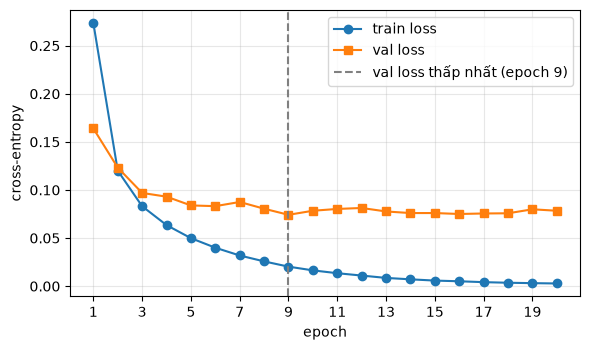

Epoch có val_loss thấp nhất: 9 | val_loss = 0.0742


In [29]:
epochs = range(1, len(history["train_loss"]) + 1)
best = history["val_loss"].index(min(history["val_loss"])) + 1   # TODO 13: epoch có val_loss nhỏ nhất, tính từ 1

plt.figure(figsize=(6, 3.6))
plt.plot(epochs, history["train_loss"], "o-", label="train loss")
plt.plot(epochs, history["val_loss"],   "s-", label="val loss")
plt.axvline(best, ls="--", c="gray",
            label=f"val loss thấp nhất (epoch {best})")
plt.xlabel("epoch"); plt.ylabel("cross-entropy")
plt.xticks(list(epochs)[::2])
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()
print("Epoch có val_loss thấp nhất:", best,
      "| val_loss =", round(min(history["val_loss"]), 4))

assert history["val_loss"][best - 1] == min(history["val_loss"])

In [30]:
from sklearn.metrics import (accuracy_score, classification_report,
                             precision_recall_fscore_support,
                             confusion_matrix, ConfusionMatrixDisplay)

_, y_true, y_pred = evaluate(model, test_loader, nn.CrossEntropyLoss())
# TODO 14: precision, recall, F1 macro
p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro")

print(f"Accuracy       : {accuracy_score(y_true, y_pred):.4f}")
print(f"Precision macro: {p:.4f}")
print(f"Recall macro   : {r:.4f}")
print(f"F1 macro       : {f1:.4f}")

Accuracy       : 0.9796
Precision macro: 0.9796
Recall macro   : 0.9795
F1 macro       : 0.9795


In [31]:
print(classification_report(y_true, y_pred, digits=4))

              precision    recall  f1-score   support

           0     0.9758    0.9888    0.9823       980
           1     0.9894    0.9885    0.9890      1135
           2     0.9730    0.9767    0.9749      1032
           3     0.9764    0.9842    0.9803      1010
           4     0.9767    0.9837    0.9802       982
           5     0.9853    0.9798    0.9826       892
           6     0.9842    0.9781    0.9812       958
           7     0.9795    0.9757    0.9776      1028
           8     0.9723    0.9743    0.9733       974
           9     0.9828    0.9653    0.9740      1009

    accuracy                         0.9796     10000
   macro avg     0.9796    0.9795    0.9795     10000
weighted avg     0.9796    0.9796    0.9796     10000



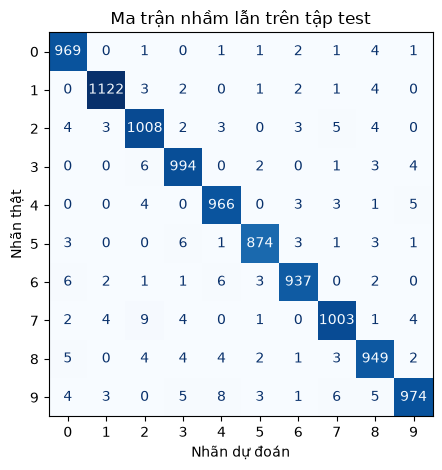

5 cặp (thật -> đoán) nhầm nhiều nhất:
  7 -> 2: 9 ảnh
  9 -> 4: 8 ảnh
  6 -> 4: 6 ảnh
  9 -> 7: 6 ảnh
  6 -> 0: 6 ảnh


In [32]:
# TODO 15: ma trận nhầm lẫn
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap="Blues", colorbar=False)
disp.ax_.set_xlabel("Nhãn dự đoán")
disp.ax_.set_ylabel("Nhãn thật")
plt.title("Ma trận nhầm lẫn trên tập test"); plt.tight_layout(); plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
print("5 cặp (thật -> đoán) nhầm nhiều nhất:")
for idx in off.ravel().argsort()[::-1][:5]:
    t, pr = divmod(idx, 10)
    print(f"  {t} -> {pr}: {off[t, pr]} ảnh")

assert cm.shape == (10, 10) and cm.sum() == 10_000